# What made some of my Fortnite maps take off

I have published 52 maps in Fortnite (an online game where players can also build their own game modes and share them with everyone). A few of them reached tens of thousands of players at once, and most of them never got past a few hundred. This notebook looks at all 52 to see what the successful ones have in common.

The numbers are public stats from fortnite.gg, pulled on October 17, 2026. They are totals for each map, so there is nothing about individual players in the data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

maps = pd.read_csv("data/maps.csv", parse_dates=["release_date", "peak_date", "last_updated"])

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

from matplotlib.ticker import FuncFormatter

def short(n):
    for unit, size in (("B", 1e9), ("M", 1e6), ("K", 1e3)):
        if n >= size:
            return f"{n / size:g}{unit}"
    return f"{n:g}"

nice_axis = FuncFormatter(lambda v, _: short(v))
NAMES = {"Kick a Lucky Rot": "Kick a Lucky Rot", "WINTER GUN GAME ONE SHOT DRIVE": "Winter Gun Game",
         "SUMMER RED VS BLUE SUPER HERO": "Summer Red vs Blue", "ESCAPE PRISON FOR BRAINROTS": "Escape Prison for Brainrots"}

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"images/{name}.png", bbox_inches="tight")

print(len(maps), "maps,", f"{maps.minutes_played.sum():,}", "minutes played in total")
maps.head()

52 maps, 1,219,239,190 minutes played in total


,release_date,map_name,island_code,genre,peak_players,peak_date,days_to_peak,minutes_played,favorites,max_players,updates_published,last_updated,status,studio_account,tags
0,2023-10-16,Pirate Parkour,0203-9866-6823,Parkour / Deathrun,2910.0,2023-11-10,25.0,8500000,30700,6,11,2023-11-13,Disabled,smutistudio,"deathrun, parkour, difficulty: easy, just for fun"
1,2023-11-22,SUMMER RED VS BLUE SUPER HERO,3113-4533-9063,Team Deathmatch (Red vs Blue),19123.0,2023-12-03,11.0,184800000,564900,20,47,2024-09-29,Disabled,smutistudio,"team deathmatch, action, practice, just for fun"
2,2023-12-08,CHRISTMAS RED VS BLUE,4848-6674-5987,Team Deathmatch (Red vs Blue),2011.0,2023-12-11,3.0,13000000,17900,20,5,2023-12-22,Disabled,smutistudio,"team deathmatch, practice, battle, heroes"
3,2023-12-16,NEW YEAR RED VS BLUE,3692-8457-5489,Team Deathmatch (Red vs Blue),4460.0,2024-01-01,16.0,24200000,39900,20,6,2023-12-31,Disabled,smutistudio,"winterfest, battle, team deathmatch, practice"
4,2023-12-28,ZODIAC BOX PVP,5166-4802-4083,Box Fight PvP,6262.0,2024-01-01,4.0,6300000,29500,12,4,2024-01-01,Disabled,smutistudio,"boxfight, practice, pvp, minigame"


## 1. A few maps did almost all of the work

If I sort the maps from most played to least played and add up their minutes, the curve shoots up almost straight away.

Top map: 56.4%, top 3: 77.3%, top 5: 83.6%, bottom 26 maps together: 0.3%


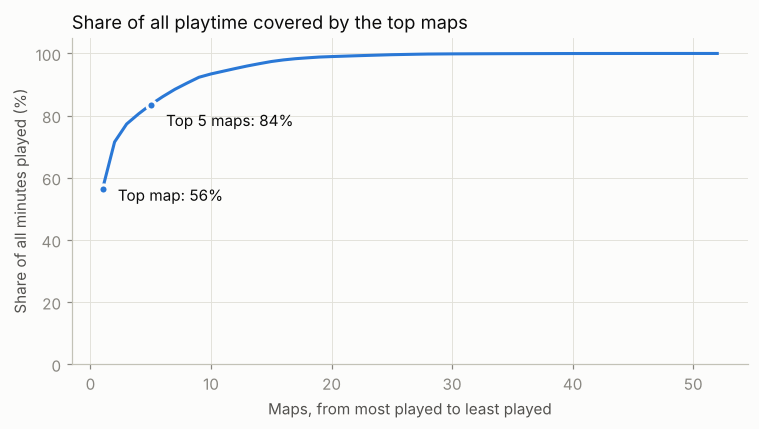

In [2]:
ranked = maps.sort_values("minutes_played", ascending=False).reset_index(drop=True)
share = ranked.minutes_played.cumsum() / ranked.minutes_played.sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(share) + 1), share * 100, color=BLUE, linewidth=2)
ax.scatter([1, 5], [share[0] * 100, share[4] * 100], color=BLUE, s=36, zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.annotate(f"Top map: {share[0]:.0%}", (1, share[0] * 100), xytext=(10, -4), textcoords="offset points", color=INK, va="center")
ax.annotate(f"Top 5 maps: {share[4]:.0%}", (5, share[4] * 100), xytext=(10, -14), textcoords="offset points", color=INK)
ax.set_xlabel("Maps, from most played to least played")
ax.set_ylabel("Share of all minutes played (%)")
ax.set_ylim(0, 105)
ax.set_title("Share of all playtime covered by the top maps", loc="left", color=INK)
save(fig, "playtime_concentration")

bottom_half = ranked.minutes_played[26:].sum() / ranked.minutes_played.sum()
print(f"Top map: {share[0]:.1%}, top 3: {share[2]:.1%}, top 5: {share[4]:.1%}, bottom 26 maps together: {bottom_half:.1%}")

Kick a Lucky Rot alone has 56% of all the minutes ever played on my maps, and the top five have 84%. The 26 least played maps together have 0.3%. So this works like music or films, where one hit matters more than many average releases, and every new map is a bet on finding the next hit.

## 2. Most maps peak in the first days, the biggest ones keep growing

For every map I counted how many days passed between release and its all-time peak.

Median days to peak: 2
Maps that peaked within 2 days of release: 53%
Spearman correlation between peak size and days to peak: 0.50 (p = 0.0002)


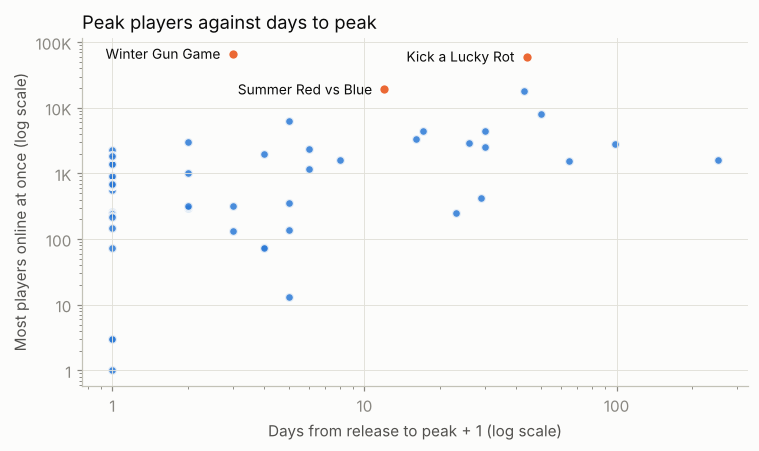

In [3]:
peaked = maps.dropna(subset=["peak_players"]).copy()
rho, p = spearmanr(peaked.peak_players, peaked.days_to_peak)
print(f"Median days to peak: {peaked.days_to_peak.median():.0f}")
print(f"Maps that peaked within 2 days of release: {(peaked.days_to_peak <= 2).mean():.0%}")
print(f"Spearman correlation between peak size and days to peak: {rho:.2f} (p = {p:.4f})")

top = peaked.nlargest(3, "peak_players")
fig, ax = plt.subplots(figsize=(7, 4.2))
rest = peaked.drop(top.index)
ax.scatter(rest.days_to_peak + 1, rest.peak_players, color=BLUE, s=34, alpha=0.85, edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(top.days_to_peak + 1, top.peak_players, color=ORANGE, s=48, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
for _, r in top.iterrows():
    ax.annotate(NAMES[r.map_name], (r.days_to_peak + 1, r.peak_players), xytext=(-8, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9, color=INK)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(nice_axis); ax.yaxis.set_major_formatter(nice_axis)
ax.set_xlabel("Days from release to peak + 1 (log scale)")
ax.set_ylabel("Most players online at once (log scale)")
ax.set_title("Peak players against days to peak", loc="left", color=INK)
save(fig, "days_to_peak")

Half of the maps hit their record within two days of release, which is most likely the extra exposure a new map gets in Fortnite's discovery screen, and once that runs out most maps fade. The biggest ones behave differently. Kick a Lucky Rot peaked 43 days after release and Escape Prison for Brainrots after 42, so they kept growing for weeks. A map that is still growing after the first week is a much better sign than a big first day.

## 3. Updates and playtime go together

Some maps got one or two updates, Kick a Lucky Rot got 267.

Spearman correlation between updates and minutes played: 0.68 (p = 3.6e-08)
updates_published
fewer than 15 updates      158300.0
15 or more updates       23200000.0
Name: minutes_played, dtype: float64


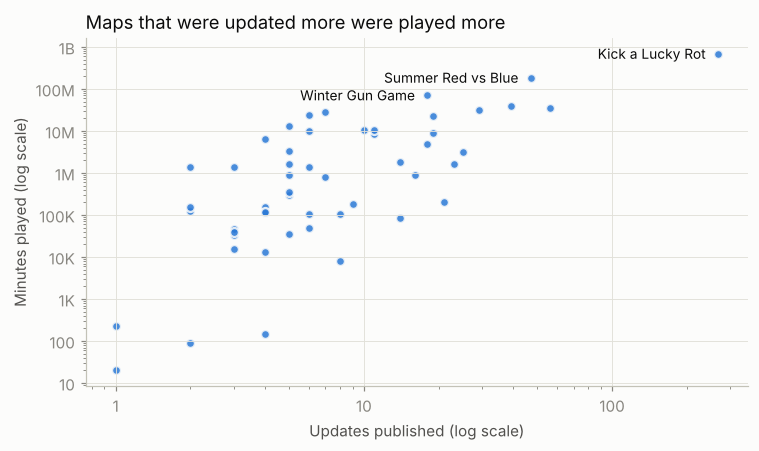

In [4]:
rho, p = spearmanr(maps.updates_published, maps.minutes_played)
print(f"Spearman correlation between updates and minutes played: {rho:.2f} (p = {p:.1e})")
print(maps.groupby(maps.updates_published >= 15).minutes_played.median().rename({False: "fewer than 15 updates", True: "15 or more updates"}))

labels = maps.nlargest(3, "minutes_played")
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(maps.updates_published, maps.minutes_played, color=BLUE, s=34, alpha=0.85, edgecolor="#fcfcfb", linewidth=1.5)
for _, r in labels.iterrows():
    ax.annotate(NAMES[r.map_name], (r.updates_published, r.minutes_played), xytext=(-8, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9, color=INK)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(nice_axis); ax.yaxis.set_major_formatter(nice_axis)
ax.set_xlabel("Updates published (log scale)")
ax.set_ylabel("Minutes played (log scale)")
ax.set_title("Maps that were updated more were played more", loc="left", color=INK)
save(fig, "updates_vs_minutes")

The median map with 15 or more updates has about 23 million minutes played, and the median map with fewer updates has about 160 thousand. This does not prove that updates cause success, because it works both ways: I update a map more when people are already playing it. What it does show is that none of the big maps got there without constant work after release.

## 4. Tycoon maps keep players much longer

Favorites are a rough count of fans. Minutes per favorite shows how long fans actually stay.

                               maps    minutes  favorites  \
genre                                                       
PvP                               1      13400         77   
Box Fight PvP                     2    9400000      38300   
Free-for-All Shooter             10   55016070     177589   
Team Deathmatch (Red vs Blue)    11  300427400     879241   
Parkour / Deathrun                6   13908400      40528   
PvP Minigame                      3    1038100       2624   
Prop Hunt / Party                 1   10500000      22800   
Gun Game (FFA shooter)           14   95027720     136482   
Party / PvP Minigame              2   10608100       8227   
Tycoon / Simulator                2  723300000     437600   

                               minutes_per_favorite  
genre                                                
PvP                                           174.0  
Box Fight PvP                                 245.0  
Free-for-All Shooter                          310.0

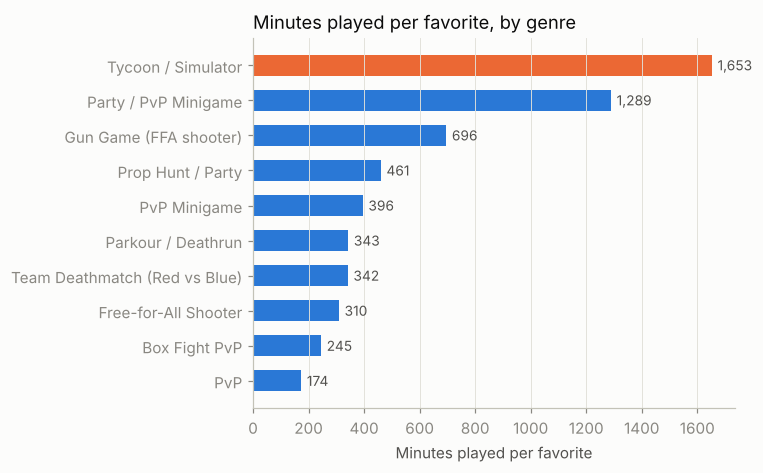

In [5]:
genres = (maps.groupby("genre")
          .agg(maps=("map_name", "size"), minutes=("minutes_played", "sum"), favorites=("favorites", "sum")))
genres["minutes_per_favorite"] = genres.minutes / genres.favorites
genres = genres.sort_values("minutes_per_favorite")
print(genres.round(0))

fig, ax = plt.subplots(figsize=(7, 4.4))
colors = [ORANGE if g == "Tycoon / Simulator" else BLUE for g in genres.index]
ax.barh(genres.index, genres.minutes_per_favorite, color=colors, height=0.6)
for y, v in enumerate(genres.minutes_per_favorite):
    ax.text(v + 20, y, f"{v:,.0f}", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("Minutes played per favorite")
ax.grid(axis="y", visible=False)
ax.set_title("Minutes played per favorite, by genre", loc="left", color=INK)
save(fig, "genre_minutes_per_favorite")

On tycoon and simulator maps, where players slowly build up money and unlock things, each fan plays about 1,650 minutes. On team deathmatch maps it is about 340. Only 2 of my 52 maps are tycoons, both released in 2026, and they have 59% of all my minutes.

## 5. Holiday and seasonal maps peaked higher

Maps with a season or holiday in the name (Winter, Christmas, New Year, Halloween, Summer) against the rest.

In [6]:
seasonal = maps.map_name.str.contains("WINTER|CHRISTMAS|NEW YEAR|SANTA|HALLOWEEN|SUMMER", case=False)
print(maps.groupby(seasonal).peak_players.agg(["count", "median"]).rename(index={False: "other maps", True: "seasonal maps"}))

               count  median
map_name                    
other maps        41   824.0
seasonal maps     10  2329.5


The median seasonal map peaked at about 2,300 players at once, almost three times more than the rest. Winter Gun Game, my highest peak at 66,671 players, came out at the end of November and peaked two days later. There are only 10 seasonal maps, so this is a pattern to test on the next releases, not a rule.

## What I take from this

1. Plan for a few hits, not for steady results. Most maps will fail, so it is better to release and test quickly and put the real work into the ones that catch on.
2. Judge a new map by its second and third week, not its first day.
3. Keep updating the maps that are growing. Kick a Lucky Rot is still live and has had 267 updates.
4. Prefer genres where players stay for a long time. Kick a Lucky Rot alone has more playtime than my other 51 maps together.

Limits: 52 maps is a small sample, the stats are public totals (no daily data or revenue), and I picked the genre for each map myself from its Fortnite tags.